In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import torch
from sklearn.model_selection import train_test_split
from torchvision import transforms
import matplotlib.pyplot as plt

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/digit-recognizer/sample_submission.csv
/kaggle/input/digit-recognizer/train.csv
/kaggle/input/digit-recognizer/test.csv


In [2]:
train_df = pd.read_csv("/kaggle/input/digit-recognizer/train.csv")
test_df = pd.read_csv("/kaggle/input/digit-recognizer/test.csv")

train_df.sample(5)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
39182,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2984,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
31374,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
14585,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
39007,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
X = (train_df.drop(columns=["label"]).values).reshape(-1, 1, 28, 28) / 255.0
y = train_df["label"].values

X_test = (test_df.values).reshape(-1, 1, 28, 28)  / 255.0

In [4]:
from torch.utils.data import Dataset, DataLoader

class MNISTDataset(Dataset):
    def __init__(self, X, y=None, transform=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long) if y is not None else None
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        image = self.X[idx].squeeze()
        image = transforms.ToPILImage()(image)
    
        if self.transform:
            image = self.transform(image)
    
        if self.y is not None:
            return image, self.y[idx]
        else:
            return image

In [5]:
train_transform = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)),  # slight rotation and shift
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

In [6]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, random_state=42)

train_dataset = MNISTDataset(X_train, y_train, transform=train_transform)
val_dataset = MNISTDataset(X_val, y_val, transform=test_transform)
test_dataset = MNISTDataset(X_test, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256)
test_loader = DataLoader(test_dataset, batch_size=256)

In [7]:
class MNISTCNNModel(torch.nn.Module):
    def __init__(self):
        super(MNISTCNNModel, self).__init__()
        self.conv1 = torch.nn.Conv2d(1, 32, kernel_size=3)
        self.conv2 = torch.nn.Conv2d(32, 64, kernel_size=3)
        self.pool = torch.nn.MaxPool2d(2, 2)
        self.fc1 = torch.nn.Linear(1600, 128)
        self.fc2 = torch.nn.Linear(128, 10)
        self.dropout = torch.nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(torch.nn.functional.relu(self.conv1(x)))
        x = self.pool(torch.nn.functional.relu(self.conv2(x)))
        x = x.view(-1, 1600)
        x = self.dropout(torch.nn.functional.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MNISTCNNModel().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = torch.nn.CrossEntropyLoss()

In [9]:
def train(model, loader):
    model.train()
    running_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    return running_loss / len(loader.dataset)


def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return correct / total

In [10]:
train_losses = []
val_accuracies = []

for epoch in range(1, 20):
    train_loss = train(model, train_loader)
    val_accuracy = evaluate(model, val_loader)

    train_losses.append(train_loss)
    val_accuracies.append(val_accuracy)

    print(f"Epoch {epoch}: Train Loss = {train_loss:.4f}, Val Accuracy = {val_accuracy:.4f}")

Epoch 1: Train Loss = 0.5400, Val Accuracy = 0.9752
Epoch 2: Train Loss = 0.2454, Val Accuracy = 0.9790
Epoch 3: Train Loss = 0.1856, Val Accuracy = 0.9848
Epoch 4: Train Loss = 0.1542, Val Accuracy = 0.9869
Epoch 5: Train Loss = 0.1362, Val Accuracy = 0.9888
Epoch 6: Train Loss = 0.1198, Val Accuracy = 0.9893
Epoch 7: Train Loss = 0.1131, Val Accuracy = 0.9895
Epoch 8: Train Loss = 0.1050, Val Accuracy = 0.9902
Epoch 9: Train Loss = 0.0960, Val Accuracy = 0.9910
Epoch 10: Train Loss = 0.0958, Val Accuracy = 0.9917
Epoch 11: Train Loss = 0.0903, Val Accuracy = 0.9895
Epoch 12: Train Loss = 0.0853, Val Accuracy = 0.9902
Epoch 13: Train Loss = 0.0852, Val Accuracy = 0.9879
Epoch 14: Train Loss = 0.0756, Val Accuracy = 0.9929
Epoch 15: Train Loss = 0.0744, Val Accuracy = 0.9893
Epoch 16: Train Loss = 0.0723, Val Accuracy = 0.9917
Epoch 17: Train Loss = 0.0686, Val Accuracy = 0.9924
Epoch 18: Train Loss = 0.0661, Val Accuracy = 0.9912
Epoch 19: Train Loss = 0.0665, Val Accuracy = 0.9914


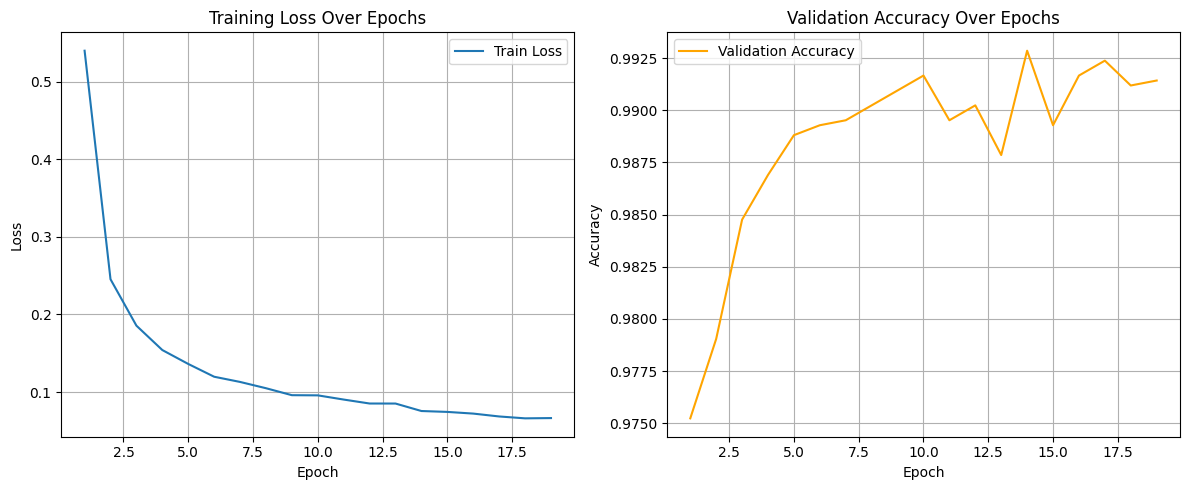

In [11]:
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label='Train Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.grid(True)
plt.legend()

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(epochs, val_accuracies, label='Validation Accuracy', color='orange')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy Over Epochs")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
model.eval()
all_preds = []

with torch.no_grad():
    for images in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())

In [13]:
import pandas as pd

submission = pd.DataFrame({
    "ImageId": list(range(1, len(all_preds) + 1)),
    "Label": all_preds
})

submission.to_csv("submission.csv", index=False)